# Adversarial ML Evasion & Layered Robustness Lab for Cybersecurity Classifiers

This interactive notebook reproduces the complete white-box evasion and layered hardening pipeline for tabular Intrusion Detection System (IDS) network-flow classifiers:

1. **Domain-Constrained Flow Telemetry (`data/dataset_loader.py`)**: Partitioning network flow features into locked discrete protocol headers ($M_j = 0$) and bounded continuous flow kinematics ($M_j = 1$, $x_j \in [x_{\min, j}, x_{\max, j}]$).
2. **Unhardened Baseline Neural IDS (`models/ids_classifier.py`)**: Training `RobustIDSNet` (`BatchNorm1d` + `LeakyReLU` + `Dropout`) with class-weighted cross-entropy and early stopping.
3. **White-Box Gradient Sensitivity (`robustness/gradient_eval.py`)**: Evaluating masked FGSM and iterative PGD-20 across $\epsilon \in \{0.0, 0.02, 0.05, 0.10, 0.15, 0.20\}$ while auditing exact protocol invariance.
4. **Layered Hardening (`defenses/hardening.py`)**: Restoring resilience via **Feature Squeezing**, **Min-Max PGD Adversarial Training (PGD-AT)**, and **Class-Conditional Mahalanobis + Entropy OOD Rejection**.

**Evaluation caveat:** Attacks target the underlying classifiers, not the complete squeezing or rejection pipeline. They are non-adaptive and do not certify robustness; evaluate BPDA and detector-aware attacks separately. The full-stack adversarial defense rate counts rejection as success and is not classification accuracy. Synthetic bounded features need not represent realizable network flows.

In [1]:
import sys
from pathlib import Path

# Ensure repository root is importable when running from notebooks/
REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from data.dataset_loader import DEFAULT_FLOW_SCHEMA, generate_synthetic_flows
from models.ids_classifier import TrainingConfig, evaluate_classifier, set_deterministic_seed, train_baseline_classifier
from robustness.gradient_eval import analyze_feature_vulnerability, fgsm_attack, pgd_attack, verify_perturbation_constraints
from defenses.hardening import (
    FeatureSqueezer,
    HardenedIDSStack,
    MahalanobisOODDetector,
    PGDATConfig,
    compute_ood_auroc,
    train_pgd_adversarial,
)

%matplotlib inline
set_deterministic_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Repository Root: {REPO_ROOT}")
print(f"PyTorch Version: {torch.__version__} | Device: {DEVICE}")

Repository Root: /home/user/Adversarial-ML-Evasion-Robustness-Lab
PyTorch Version: 2.15.0+cu132 | Device: cpu


## 1. Domain-Constrained Network-Flow Dataset & Mutability Schema

We generate realistic multi-class network-flow records (`Benign`, `DoS`, `PortScan`, `BruteForce`) and inspect the explicit partitioning between **immutable protocol header features ($M_j = 0$)** and **mutable continuous flow kinematics ($M_j = 1$)**.

In [2]:
bundle = generate_synthetic_flows(n_samples=6000, seed=42, include_ood=True)
print("Dataset Summary:", bundle.summary_dict())

schema_df = pd.DataFrame([
    {
        "Feature": spec.name,
        "Category": spec.category,
        "Mutable (M_j)": int(spec.mutable),
        "Physical Min": spec.raw_min,
        "Physical Max": spec.raw_max,
        "Log-Compressed": spec.log_scale,
    }
    for spec in DEFAULT_FLOW_SCHEMA
])
schema_df

Dataset Summary: {'num_train': 3900, 'num_val': 900, 'num_test': 1200, 'num_features': 20, 'num_immutable': 6, 'num_mutable': 14, 'train_class_distribution': {'Benign': 1744, 'DoS': 868, 'PortScan': 679, 'BruteForce': 609}}


,Feature,Category,Mutable (M_j),Physical Min,Physical Max,Log-Compressed
0,protocol_tcp,protocol_header,0,0.00,1.0,False
1,protocol_udp,protocol_header,0,0.00,1.0,False
2,dst_port_tier,protocol_header,0,0.00,3.0,False
3,tcp_syn_flag,protocol_header,0,0.00,1.0,False
4,tcp_ack_flag,protocol_header,0,0.00,1.0,False
5,tcp_rst_psh_flag,protocol_header,0,0.00,1.0,False
6,flow_duration_ms,flow_macro,1,0.50,120000.0,True
7,fwd_pkt_rate,flow_macro,1,0.10,50000.0,True
8,bwd_pkt_rate,flow_macro,1,0.00,50000.0,True
9,byte_rate,flow_macro,1,20.00,50000000.0,True


## 2. Baseline `RobustIDSNet` Classifier Training

Next, we train the unhardened `RobustIDSNet` Multi-Layer Perceptron using inverse-frequency class weights, `AdamW`, `ReduceLROnPlateau` scheduling, and validation early stopping.

Clean Test Accuracy: 98.08% | Macro F1: 0.9794


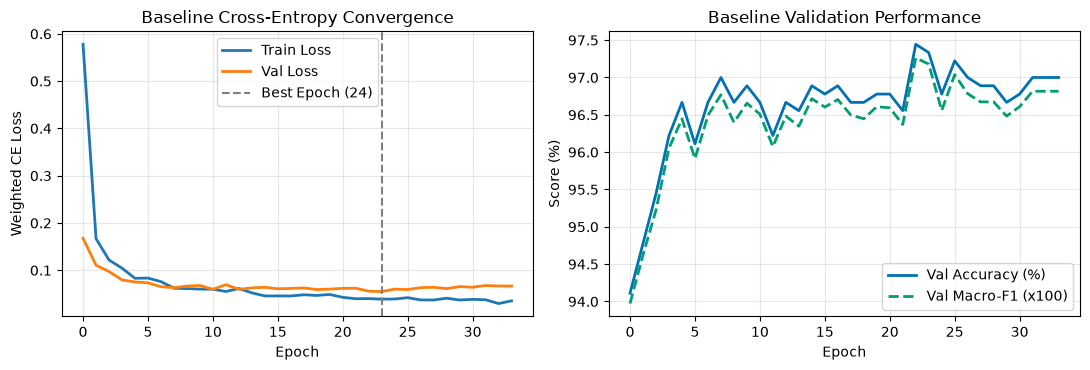

In [3]:
base_cfg = TrainingConfig(epochs=35, batch_size=128, seed=42, device=DEVICE)
baseline_model, base_hist = train_baseline_classifier(
    X_train=bundle.X_train,
    y_train=bundle.y_train,
    X_val=bundle.X_val,
    y_val=bundle.y_val,
    num_classes=bundle.schema.num_classes,
    config=base_cfg,
)

clean_metrics = evaluate_classifier(baseline_model, bundle.X_test, bundle.y_test, device=DEVICE)
print(f"Clean Test Accuracy: {clean_metrics['accuracy']*100:.2f}% | Macro F1: {clean_metrics['macro_f1']:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(base_hist.train_loss, label="Train Loss", lw=2)
ax1.plot(base_hist.val_loss, label="Val Loss", lw=2)
ax1.axvline(base_hist.best_epoch, color="gray", ls="--", label=f"Best Epoch ({base_hist.best_epoch+1})")
ax1.set_title("Baseline Cross-Entropy Convergence")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Weighted CE Loss")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(np.array(base_hist.val_accuracy) * 100.0, label="Val Accuracy (%)", color="#0072B2", lw=2)
ax2.plot(np.array(base_hist.val_macro_f1) * 100.0, label="Val Macro-F1 (x100)", color="#009E73", lw=2, ls="--")
ax2.set_title("Baseline Validation Performance")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Score (%)")
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Domain-Aware White-Box FGSM & PGD Evaluation

We craft bounded white-box FGSM and PGD-20 perturbations at $\epsilon = 0.10$ and verify that:
1. Discrete protocol features ($M_j = 0$) undergo **exact zero modification** ($x_{\text{adv}}[M=0] == x[M=0]$).
2. All perturbed samples remain strictly inside $[x_{\min}, x_{\max}] = [0, 1]^d$ and invert cleanly back to valid physical units.

In [4]:
mask_t, xmin_t, xmax_t = bundle.schema.to_torch(DEVICE)
x_test_t = torch.as_tensor(bundle.X_test, dtype=torch.float32, device=DEVICE)
y_test_t = torch.as_tensor(bundle.y_test, dtype=torch.long, device=DEVICE)

x_fgsm = fgsm_attack(baseline_model, x_test_t, y_test_t, eps=0.10, mutability_mask=mask_t, x_min=xmin_t, x_max=xmax_t)
x_pgd = pgd_attack(baseline_model, x_test_t, y_test_t, eps=0.10, mutability_mask=mask_t, x_min=xmin_t, x_max=xmax_t, steps=20, seed=42)

constraint_chk = verify_perturbation_constraints(x_test_t, x_pgd, eps=0.10, mutability_mask=mask_t, x_min=xmin_t, x_max=xmax_t)
fgsm_acc = (baseline_model.predict(x_fgsm) == y_test_t).float().mean().item()
pgd_acc = (baseline_model.predict(x_pgd) == y_test_t).float().mean().item()

print("Constraint Audit (PGD @ eps=0.10):", constraint_chk)
print(f"Unhardened Baseline -> Clean: {clean_metrics['accuracy']*100:.2f}% | FGSM(0.10): {fgsm_acc*100:.2f}% | PGD-20(0.10): {pgd_acc*100:.2f}%")

Constraint Audit (PGD @ eps=0.10): {'valid': True, 'immutable_preserved': True, 'within_linf_ball': True, 'within_domain_bounds': True, 'is_finite': True, 'max_immutable_delta': 0.0, 'max_linf_delta': 0.10000002384185791, 'max_bound_violation': 0.0}
Unhardened Baseline -> Clean: 98.08% | FGSM(0.10): 25.33% | PGD-20(0.10): 21.58%


## 4. Layered ML Hardening: Feature Squeezing, PGD-AT & Mahalanobis OOD Detection

We now deploy all three layered defenses:
- **Defense 1 (PGD-AT)**: Min-max saddle-point optimization dynamically generating PGD perturbations inside each mini-batch.
- **Defense 2 (Feature Squeezing)**: Metric-space Gaussian kernel smoothing + 4-bit precision quantization on mutable features.
- **Defense 3 (Mahalanobis + Entropy Detector)**: Class-conditional Gaussian manifold $(\mu_c, \Sigma^{-1})$ fitted on penultimate embeddings to quarantine off-manifold evasions and unseen zero-day flows.

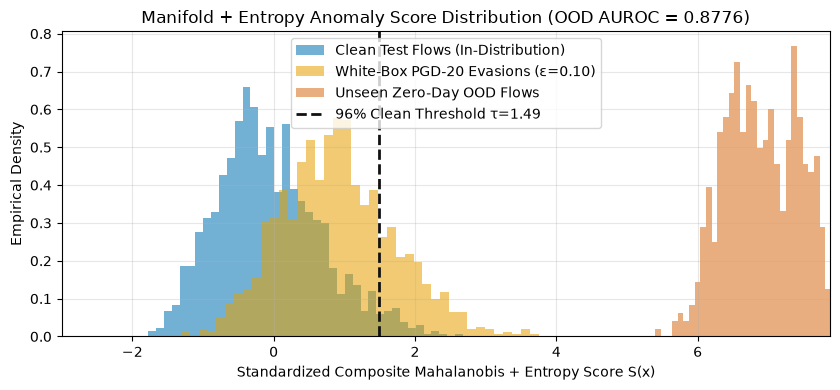

In [5]:
squeezer = FeatureSqueezer(schema=bundle.schema, bit_depth=4, smoothing="gaussian").fit(bundle.X_train)

pgdat_cfg = PGDATConfig(
    epochs=35,
    batch_size=128,
    train_eps=0.11,
    pgd_steps=10,
    adv_mix_weight=0.65,
    seed=42,
    device=DEVICE,
)
pgdat_model, pgdat_hist = train_pgd_adversarial(
    X_train=bundle.X_train,
    y_train=bundle.y_train,
    X_val=bundle.X_val,
    y_val=bundle.y_val,
    schema=bundle.schema,
    config=pgdat_cfg,
)

detector = MahalanobisOODDetector(target_fpr=0.04).fit(
    model=pgdat_model,
    X_train=bundle.X_train,
    y_train=bundle.y_train,
    X_val=bundle.X_val,
    device=DEVICE,
)
light_sq = FeatureSqueezer(schema=bundle.schema, bit_depth=5, smoothing="none").fit(bundle.X_train)
full_stack = HardenedIDSStack(model=pgdat_model, detector=detector, squeezer=light_sq, device=DEVICE)

# Visualize Mahalanobis + Entropy Anomaly Score separation
x_at_pgd10 = pgd_attack(pgdat_model, x_test_t, y_test_t, eps=0.10, mutability_mask=mask_t, x_min=xmin_t, x_max=xmax_t, steps=20, seed=42).cpu().numpy()
scores_clean = detector.anomaly_score(pgdat_model, bundle.X_test, device=DEVICE)
scores_adv = detector.anomaly_score(pgdat_model, x_at_pgd10, device=DEVICE)
scores_ood = detector.anomaly_score(pgdat_model, bundle.X_ood, device=DEVICE)
auroc_combined = compute_ood_auroc(scores_clean, np.concatenate([scores_adv, scores_ood]))

plt.figure(figsize=(8.5, 4.0))
plt.hist(scores_clean, bins=40, density=True, alpha=0.55, color="#0072B2", label="Clean Test Flows (In-Distribution)")
plt.hist(scores_adv, bins=40, density=True, alpha=0.55, color="#E69F00", label="White-Box PGD-20 Evasions (ε=0.10)")
plt.hist(scores_ood, bins=40, density=True, alpha=0.50, color="#D55E00", label="Unseen Zero-Day OOD Flows")
plt.axvline(detector.threshold_, color="#111111", ls="--", lw=2, label=f"96% Clean Threshold τ={detector.threshold_:.2f}")
plt.title(f"Manifold + Entropy Anomaly Score Distribution (OOD AUROC = {auroc_combined:.4f})")
plt.xlabel("Standardized Composite Mahalanobis + Entropy Score S(x)")
plt.ylabel("Empirical Density")
plt.xlim(-3.0, np.percentile(np.concatenate([scores_adv, scores_ood]), 98))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Full Tradeoff Curves & Feature Vulnerability Ranking

Finally, we evaluate all four configurations across $\epsilon \in \{0.00, 0.02, 0.05, 0.10, 0.15, 0.20\}$ and visualize both the **Clean vs. Robust Accuracy Tradeoff Curve** and **Input Gradient Vulnerability Ranking**.

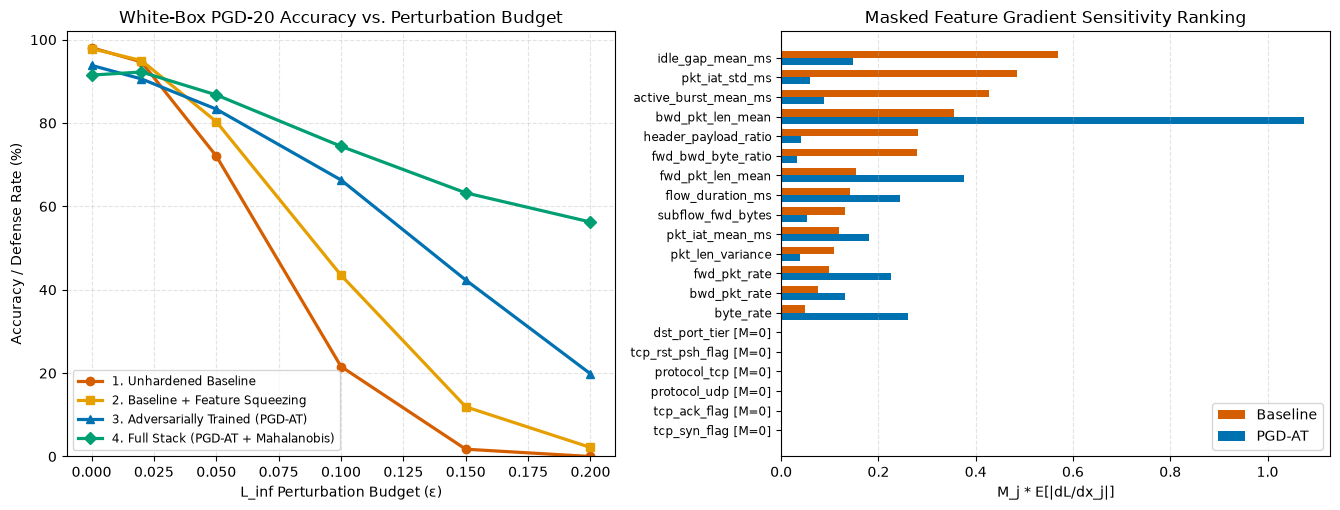

,Configuration,Clean Acc (ε=0.00),PGD-20 Acc (ε=0.05),PGD-20 Acc (ε=0.10),PGD-20 Acc (ε=0.20)
0,1. Unhardened Baseline,98.08%,72.08%,21.58%,0.00%
1,2. Baseline + Feature Squeezing,97.83%,80.33%,43.50%,2.17%
2,3. Adversarially Trained (PGD-AT),93.83%,83.33%,66.33%,19.83%
3,4. Full Stack (PGD-AT + Mahalanobis),91.50%,86.75%,74.42%,56.25%


In [6]:
epsilons = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20]
curves = {
    "1. Unhardened Baseline": [],
    "2. Baseline + Feature Squeezing": [],
    "3. Adversarially Trained (PGD-AT)": [],
    "4. Full Stack (PGD-AT + Mahalanobis)": [],
}

for eps in epsilons:
    xb_adv = pgd_attack(baseline_model, x_test_t, y_test_t, eps=eps, mutability_mask=mask_t, x_min=xmin_t, x_max=xmax_t, steps=20, seed=42)
    xa_adv = pgd_attack(pgdat_model, x_test_t, y_test_t, eps=eps, mutability_mask=mask_t, x_min=xmin_t, x_max=xmax_t, steps=20, seed=42)

    acc_base = (baseline_model.predict(xb_adv) == y_test_t).float().mean().item()
    acc_sq = (squeezer.predict(baseline_model, xb_adv) == y_test_t).float().mean().item()
    acc_at = (pgdat_model.predict(xa_adv) == y_test_t).float().mean().item()

    det = full_stack.predict_detailed(xa_adv)
    if eps == 0.0:
        acc_full = float(np.mean((~det.is_rejected) & (det.raw_predictions == bundle.y_test)))
    else:
        acc_full = float(np.mean((det.raw_predictions == bundle.y_test) | det.is_rejected))

    curves["1. Unhardened Baseline"].append(acc_base * 100.0)
    curves["2. Baseline + Feature Squeezing"].append(acc_sq * 100.0)
    curves["3. Adversarially Trained (PGD-AT)"].append(acc_at * 100.0)
    curves["4. Full Stack (PGD-AT + Mahalanobis)"].append(acc_full * 100.0)

base_vuln = analyze_feature_vulnerability(baseline_model, bundle.X_test, bundle.y_test, bundle.schema, eps=0.10, device=DEVICE)
pgdat_vuln = analyze_feature_vulnerability(pgdat_model, bundle.X_test, bundle.y_test, bundle.schema, eps=0.10, device=DEVICE)

fig, (ax_c, ax_v) = plt.subplots(1, 2, figsize=(13.5, 5.2))
colors = ["#D55E00", "#E69F00", "#0072B2", "#009E73"]
markers = ["o", "s", "^", "D"]
for (label, vals), col, mk in zip(curves.items(), colors, markers):
    ax_c.plot(epsilons, vals, label=label, color=col, marker=mk, lw=2.3)
ax_c.set_title("White-Box PGD-20 Accuracy vs. Perturbation Budget")
ax_c.set_xlabel("L_inf Perturbation Budget (ε)")
ax_c.set_ylabel("Accuracy / Defense Rate (%)")
ax_c.set_ylim(0, 102)
ax_c.grid(alpha=0.35, ls="--")
ax_c.legend(loc="lower left", fontsize=8.8)

order = np.lexsort((base_vuln.raw_grad_sensitivity, base_vuln.effective_grad_sensitivity, base_vuln.mutability_mask))
y_pos = np.arange(len(order))
labels_v = [base_vuln.feature_names[i] + (" [M=0]" if base_vuln.mutability_mask[i] == 0 else "") for i in order]
ax_v.barh(y_pos + 0.18, base_vuln.effective_grad_sensitivity[order], height=0.36, color="#D55E00", label="Baseline")
ax_v.barh(y_pos - 0.18, pgdat_vuln.effective_grad_sensitivity[order], height=0.36, color="#0072B2", label="PGD-AT")
ax_v.set_yticks(y_pos)
ax_v.set_yticklabels(labels_v, fontsize=8.5)
ax_v.set_title("Masked Feature Gradient Sensitivity Ranking")
ax_v.set_xlabel("M_j * E[|dL/dx_j|]")
ax_v.grid(axis="x", alpha=0.35, ls="--")
ax_v.legend(loc="lower right")
plt.tight_layout()
plt.show()

summary_df = pd.DataFrame({
    "Configuration": list(curves.keys()),
    "Clean Acc (ε=0.00)": [f"{v[0]:.2f}%" for v in curves.values()],
    "PGD-20 Acc (ε=0.05)": [f"{v[2]:.2f}%" for v in curves.values()],
    "PGD-20 Acc (ε=0.10)": [f"{v[3]:.2f}%" for v in curves.values()],
    "PGD-20 Acc (ε=0.20)": [f"{v[5]:.2f}%" for v in curves.values()],
})
summary_df